In [1]:
import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"D:\Nikss\Self Pracitce\ML (Picked from middle)\01 IPL dataset.csv")

In [3]:
df.head()

,Unnamed: 0,batting_team,bowling_team,city,runs_left,balls_left,wickets_remaining,total_run_x,crr,rrr,results
0,0,Gujarat Titans,Rajasthan Royals,Ahmedabad,131,125,10,131,-0.0,6.29,1
1,1,Gujarat Titans,Rajasthan Royals,Ahmedabad,131,124,10,131,-0.0,6.34,1
2,2,Gujarat Titans,Rajasthan Royals,Ahmedabad,126,119,10,131,30.0,6.35,1
3,3,Gujarat Titans,Rajasthan Royals,Ahmedabad,122,118,10,131,27.0,6.20,1
4,4,Gujarat Titans,Rajasthan Royals,Ahmedabad,122,117,10,131,18.0,6.26,1


In [4]:
df.drop(columns = 'Unnamed: 0', inplace = True)

In [5]:
df.head()

,batting_team,bowling_team,city,runs_left,balls_left,wickets_remaining,total_run_x,crr,rrr,results
0,Gujarat Titans,Rajasthan Royals,Ahmedabad,131,125,10,131,-0.0,6.29,1
1,Gujarat Titans,Rajasthan Royals,Ahmedabad,131,124,10,131,-0.0,6.34,1
2,Gujarat Titans,Rajasthan Royals,Ahmedabad,126,119,10,131,30.0,6.35,1
3,Gujarat Titans,Rajasthan Royals,Ahmedabad,122,118,10,131,27.0,6.20,1
4,Gujarat Titans,Rajasthan Royals,Ahmedabad,122,117,10,131,18.0,6.26,1


In [6]:
df.describe()

,runs_left,balls_left,wickets_remaining,total_run_x,crr,rrr,results
count,106604.000000,106604.000000,106604.000000,106604.000000,106604.000000,106604.000000,106604.000000
mean,90.539032,66.654497,7.428511,166.862397,9.654382,8.572438,0.433042
std,48.536013,32.164333,2.139389,29.410008,5.944946,4.426402,0.495499
min,0.000000,4.000000,0.000000,63.000000,-0.000000,0.000000,0.000000
25%,52.000000,40.000000,6.000000,148.000000,7.380000,6.480000,0.000000
50%,89.000000,67.000000,8.000000,166.000000,8.680000,8.140000,0.000000
75%,126.000000,94.000000,9.000000,186.000000,10.310000,9.860000,1.000000
max,264.000000,125.000000,10.000000,264.000000,162.000000,131.000000,1.000000


In [7]:
df.isnull().sum()

batting_team         0
bowling_team         0
city                 0
runs_left            0
balls_left           0
wickets_remaining    0
total_run_x          0
crr                  0
rrr                  0
results              0
dtype: int64

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 106604 entries, 0 to 106603
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   batting_team       106604 non-null  object 
 1   bowling_team       106604 non-null  object 
 2   city               106604 non-null  object 
 3   runs_left          106604 non-null  int64  
 4   balls_left         106604 non-null  int64  
 5   wickets_remaining  106604 non-null  int64  
 6   total_run_x        106604 non-null  int64  
 7   crr                106604 non-null  float64
 8   rrr                106604 non-null  float64
 9   results            106604 non-null  int64  
dtypes: float64(2), int64(5), object(3)
memory usage: 8.1+ MB


In [9]:
df['balls_left'] = np.where(df.balls_left >120, 120, df.balls_left)

In [10]:
df[df.balls_left> 120]

,batting_team,bowling_team,city,runs_left,balls_left,wickets_remaining,total_run_x,crr,rrr,results


In [11]:
# Changing teams name:

team = {
    'Gujarat Titans': 'Gujarat Lions'
}

df['bowling_team'] = df.bowling_team.replace(team)

df['batting_team'] = df.batting_team.replace(team)

In [12]:
df.bowling_team.unique()

array(['Rajasthan Royals', 'Royal Challengers Bangalore',
       'Sunrisers Hyderabad', 'Delhi Capitals', 'Chennai Super Kings',
       'Gujarat Lions', 'Lucknow Super Giants', 'Kolkata Knight Riders',
       'Punjab Kings', 'Mumbai Indians', 'Rising Pune Supergiant',
       'Rising Pune Supergiants', 'Pune Warriors', 'Kochi Tuskers Kerala'],
      dtype=object)

In [13]:
# Keeping only teams which are currently playing

teams = ['Gujarat Titans',
        'Rajasthan Royals',
        'Punjab Kings',
        'Mumbai Indians', 
        'Royal Challengers Bangalore',
        'Kolkata Knight Riders',
        'Sunrisers Hyderabad',
        'Delhi Capitals',
       'Chennai Super Kings',
        'Lucknow Super Giants']

df = df[df['batting_team'].isin(teams)]
df = df[df.bowling_team.isin(teams)]

In [14]:
df['batting_team'].nunique()

9

In [15]:
df['city'] = df['city'].str.replace('Bangalore', 'Bengaluru')

In [16]:
# Here, we have 3 categorical columns (batting_team, bowling_team and city) and seven numeric columns

# So, we will OH encode categorical columns bcz there are no orders in their values
# We will scale numeric columns.

In [17]:
# but before this, let's first split our data to train and test data

x = df.iloc[:, 0:-1]
y = df.drop(x, axis = 'columns')

In [18]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2)

In [19]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.compose import ColumnTransformer

In [20]:
# Ohe on batting_team, bowing_team and city
# Indices are 0, 1, 2

trans = [
    ('OHE', OneHotEncoder(sparse_output = False, drop = 'first', handle_unknown = 'ignore'), [0,1,2]),
    ('Scaling', StandardScaler(), [3, 4, 5, 6, 7, 8])
]

ct = ColumnTransformer(transformers = trans, remainder = 'passthrough')

# sparse = False means we dont want sparse matrix. Sparse matrix has many values as 0. Opposite to Sparse is Dense metrix
# handle_unknoen = 'ignore' means in testing or predicting, if a model gets some Unknown value like
# City is OHEncoded and it is not having and city as 'Jetpur'. But if during testing or preducting it get 'Jetpur'
# Then simply ignore

In [21]:
from sklearn.tree import DecisionTreeClassifier


In [22]:
x_train_trans = ct.fit_transform(x_train)

In [23]:
x_test_trans = ct.transform(x_test)

In [24]:
dt = DecisionTreeClassifier()

In [25]:
criterion = ['entropy', 'gini']
max_depth = [5, 8, 12, 15, 18]
min_samples_leaf = [3, 5, 7, 9, 11, 13]
min_samples_split = [2, 4, 6, 8]

In [26]:

params_grid = {
    'criterion': criterion,
    'max_depth': max_depth,
    'min_samples_leaf': min_samples_leaf,
    'min_samples_split': min_samples_split
}

In [27]:
from sklearn.model_selection import GridSearchCV


In [28]:
dt_grid = GridSearchCV(estimator = dt, param_grid = params_grid, n_jobs = -1, verbose = 2)

In [29]:
dt_grid.fit(x_train_trans, y_train)

Fitting 5 folds for each of 240 candidates, totalling 1200 fits


GridSearchCV(estimator=DecisionTreeClassifier(), n_jobs=-1,
             param_grid={'criterion': ['entropy', 'gini'],
                         'max_depth': [5, 8, 12, 15, 18],
                         'min_samples_leaf': [3, 5, 7, 9, 11, 13],
                         'min_samples_split': [2, 4, 6, 8]},
             verbose=2)

In [30]:
dt_grid.best_params_

{'criterion': 'gini',
 'max_depth': 18,
 'min_samples_leaf': 3,
 'min_samples_split': 2}

In [31]:
# Get best model

model = dt_grid.best_estimator_

In [32]:
model

DecisionTreeClassifier(max_depth=18, min_samples_leaf=3)

In [33]:
y_pred = model.predict(x_test_trans)

In [34]:
y_pred

array([1, 1, 1, ..., 1, 0, 0], dtype=int64)

In [35]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [36]:
cr = classification_report(y_pred, y_test)
print(cr)

              precision    recall  f1-score   support

           0       0.95      0.97      0.96     10346
           1       0.96      0.93      0.95      7915

    accuracy                           0.95     18261
   macro avg       0.95      0.95      0.95     18261
weighted avg       0.95      0.95      0.95     18261



In [37]:
cm = confusion_matrix(y_pred, y_test)

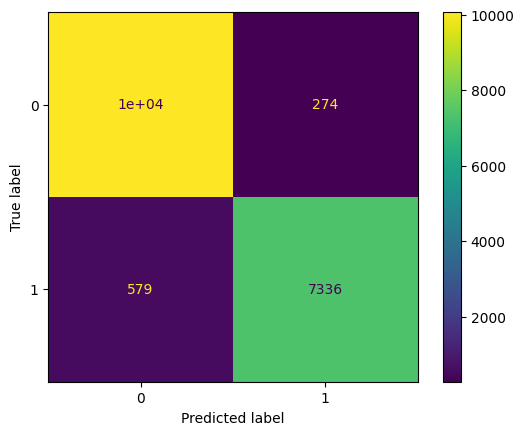

In [38]:
disp = ConfusionMatrixDisplay(cm, display_labels = [0, 1])
disp.plot()

In [39]:
from sklearn.model_selection import cross_val_score, StratifiedKFold, LeaveOneOut

In [40]:
cv = cross_val_score(model, X = x_train_trans, y = y_train, cv = 10)

In [41]:
cv.mean()

0.9647179627601314

In [42]:
skf = StratifiedKFold(n_splits = 10, shuffle = True, random_state = 1)

In [43]:
cv2 = cross_val_score(model, X = x_train_trans, y = y_train, cv = skf)

In [44]:
cv2.mean()

0.9648548740416212

In [45]:
y_pred2 = model.predict_proba(x_test_trans)

In [46]:
y_true = y_test

In [47]:
from sklearn.metrics import precision_recall_curve

In [48]:
precisions, recalls, thresholds = precision_recall_curve(y_true, y_pred2[:,1])

In [49]:
precisions

array([0.41673512, 0.85320275, 0.85691664, 0.85740154, 0.86538681,
       0.86988506, 0.8721319 , 0.87227414, 0.87257618, 0.87368543,
       0.87424803, 0.89544204, 0.90069981, 0.90144928, 0.90241838,
       0.91839523, 0.9212333 , 0.92165438, 0.92186523, 0.9233279 ,
       0.92664141, 0.92684776, 0.92942371, 0.93045137, 0.93192249,
       0.93190513, 0.93226177, 0.93378586, 0.94024788, 0.94045443,
       0.94056172, 0.9412688 , 0.9417463 , 0.94339375, 0.94410757,
       0.94530005, 0.94567672, 0.94800322, 0.94818096, 0.9487352 ,
       0.98060626, 0.98215761, 0.98633603, 0.98664864, 0.98955795,
       0.99036102, 0.99033901, 0.99049296, 0.99066244, 0.99183239,
       0.99198147, 0.99559303, 0.99576679, 0.99591599, 0.99628253,
       0.99622866, 0.9961786 , 1.        ])

In [50]:
f1_scores = (precisions * recalls) / (precisions + recalls + 1e-8)

In [51]:
f1_scores

array([0.29415175, 0.45952828, 0.46051911, 0.46065912, 0.46286902,
       0.46400981, 0.46453356, 0.46445905, 0.46454467, 0.46485888,
       0.46493171, 0.46872064, 0.46955592, 0.46972939, 0.46996221,
       0.47212821, 0.47244094, 0.47242682, 0.47241976, 0.47230246,
       0.47256922, 0.47252818, 0.4727531 , 0.47289176, 0.47301669,
       0.47294848, 0.47304032, 0.47288883, 0.47181669, 0.47170553,
       0.47166721, 0.47171419, 0.47176864, 0.47182081, 0.47130824,
       0.47021529, 0.47030847, 0.46934713, 0.46902184, 0.46875415,
       0.43772734, 0.43511674, 0.4318954 , 0.43158128, 0.42572626,
       0.42437669, 0.42381417, 0.42332581, 0.42322746, 0.4218396 ,
       0.42104069, 0.40501987, 0.40407589, 0.40158406, 0.40028299,
       0.39682163, 0.3936576 , 0.        ])

In [52]:
best_f1_index = np.argmax(f1_scores)

In [53]:
best_thres = thresholds[best_f1_index]

best_thres

0.5757575757575758

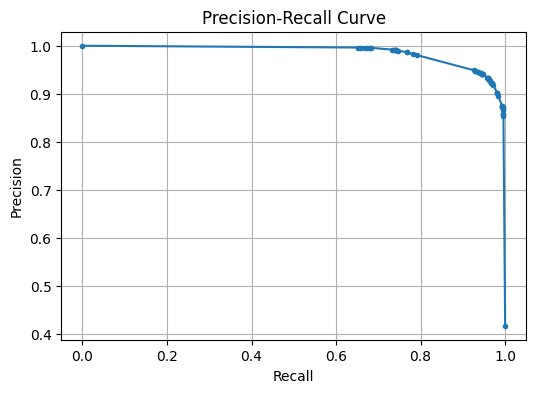

In [55]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.plot(recalls, precisions, marker='.', )
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.grid(True)
plt.show()


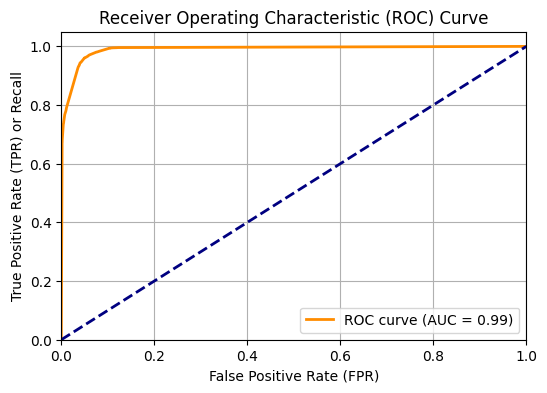

AUC Score: 0.99


In [63]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Assuming you have 'y_true' (true binary labels) and 'y_pred_proba'
# (predicted probabilities for the positive class)

# Calculate the ROC curve
fpr, tpr, thresholds = roc_curve(y_true, y_pred2[:, 1])

# Calculate the AUC score
roc_auc = roc_auc_score(y_true, y_pred2[:, 1])

# Plot the ROC curve
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  # Diagonal line representing random guessing
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR) or Recall')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print(f"AUC Score: {roc_auc:.2f}")